# WP12 — Gerçek Gemma V2 ve koşullu Qwen hazırlığı

**V2 gerçekten yanıt verdi; token sayımı kapısı başarısız ve açıklamalar yine İngilizce.** Özgün TOKEN_COUNT_ALIGNMENT_FAILED kaydı değiştirilmez. Ayrı post-hoc içerik kontrolü, sayım doğrulanmış gibi yapılmış yeni bir pipeline değerlendirmesi değildir. Kullanıcının koşullu izniyle Qwen hazırlığı açıldı; Qwen belleği yetersiz, inference NOT_RUN. Yeni istek/tekrar/model indirme/eğitim/WP13 yok.

In [1]:
from pathlib import Path
import json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():ROOT=ROOT.parent
Q=ROOT/'reports/qa/WP12/gemma_v2_review_qwen_preparation_v1'
F=ROOT/'reports/figures/WP12/gemma_v2_review_qwen_preparation_v1'
def read(p):return json.loads(Path(p).read_text(encoding='utf-8-sig'))
pd.set_option('display.max_colwidth',600);pd.set_option('display.max_columns',16)

audit=read(Q/'Gemma_V2_independent_review.json')
display(pd.DataFrame([audit['transport_generation']]).T.rename(columns={0:'gerçek_kayıt'}))
display(pd.DataFrame([audit['original_pipeline_status_preserved']]).T.rename(columns={0:'değişmeyen_sonuç'}))
print('GERÇEK MODEL CONTENT — AYNEN:')
print(read(Q/'real_comparison_v1_v2_Qwen_NOT_RUN.json')['rows'][1]['model_message_exact'])


GERÇEK MODEL CONTENT — AYNEN:
{
"schema_version": "WP12-local-llm-candidate-v2",
"status": "candidate",
"refusal_code": null,
"items": [
  {
    "explanation_tr": "Erythromycin Tablets are a pharmaceutical product containing the active ingredient erythromycin. Erythromycin is a macrolide antibiotic.",
    "source_scope": "product_identity",
    "statement_kind": "identity",
    "evidence_ids": ["quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe"]
  },
  {
    "explanation_tr": "The Erythromycin Tablets are red coloured, round, biconvex, enteric-coated tablets.",
    "source_scope": "product_identity",
    "statement_kind": "formulation",
    "evidence_ids": ["quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5"]
  }
],
"language": "tr"
}


,gerçek_kayıt
HTTP,200
done,True
done_reason,stop
server_prompt_tokens,729
offline_planned_tokens,724
output_tokens,312
server_total_seconds,8.157021
server_load_seconds,3.452087
client_block_plus_review_seconds,12.527538
generation_completed,True


,değişmeyen_sonuç
automatic_release,False
semantic_success,None
human_review,PENDING
method,WP12-local-llm-candidate-v2
source_faithfulness,PENDING_AGENT_AND_HUMAN_REVIEW
language_quality,PENDING
schema_status,NOT_EVALUABLE
application_status,NOT_EVALUABLE
status,TOKEN_COUNT_ALIGNMENT_FAILED
technical_status,FAIL


**Yorum:** HTTP200/done=true/stop,729input/312output; eski offline724.729+312=1041, context2048 ve output384 sınırları içinde. Bu hata token budget aşımı/timeout değildir. Sayım kapısı JSON incelemesinden önce durdu; saved schema/application NOT_EVALUABLE kalır. Aynı ham JSON'un ayrı salt içerik kontrolü yapılabilir ama bu kayıt geriye dönük pipeline PASS'e çevrilemez.

## Kaynak, dil ve uygulama sınırları

In [2]:

display(pd.read_csv(Q/'V2_source_vs_claim.csv')[['item','physical_page','quote_id','source_quote_exact','model_text','assessment','translation_reviewer_NOT_MODEL']])
display(pd.DataFrame(audit['independent_posthoc_content_check']['language_checks']))
display(pd.DataFrame([audit['semantic_agent_review']]).T.rename(columns={0:'ajan_incelemesi_insan_onayı_değil'}))


,item,physical_page,quote_id,source_quote_exact,model_text,assessment,translation_reviewer_NOT_MODEL
0,0,1,quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe,"The name of your medicine is Erythromycin Tablets BP 250 mg (referred to as \nErythromycin Tablets in this leaflet). Erythromycin Tablets contain the active ingredient \nerythromycin, which belongs to a group of medicines called macrolide antibiotics. \n \n",Erythromycin Tablets are a pharmaceutical product containing the active ingredient erythromycin. Erythromycin is a macrolide antibiotic.,İngilizce. Etkin madde ve sınıf kaynakta var. BP250mg ürün tanımı atlanmış; yeni klinik olgu yok.,"Erythromycin Tablets, etkin madde erythromycin içeren farmasötik bir üründür. Erythromycin bir makrolid antibiyotiktir."
1,1,6,quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5,"What Erythromycin Tablets look like and the contents of the pack \nErythromycin Tablets are red coloured, round, biconvex, enteric-coated tablets. \n \nThey are available in blister packs containing 28, 56, 84 and 100 tablets or in containers of \n21, 100, 250, 500 and 1000 tablets. \n \n","The Erythromycin Tablets are red coloured, round, biconvex, enteric-coated tablets.",İngilizce. Renk/şekil/enterik kaplama alıntıyla uyumlu. Ambalaj sayıları atlanmış; birincil quote-ID ve kind doğru.,"Erythromycin Tablets kırmızı renkli, yuvarlak, bikonveks, enterik kaplı tabletlerdir."


,status,English_markers,Turkish_markers,language_declared_tr_is_proof,human_required,automatic_success
0,PENDING_HUMAN_LANGUAGE_REVIEW,"[product, the]",[],False,True,False
1,PENDING_HUMAN_LANGUAGE_REVIEW,[the],[],False,True,False


,ajan_incelemesi_insan_onayı_değil
review_kind,AGENT_SOURCE_AND_LANGUAGE_COMPARISON_NOT_HUMAN_APPROVAL
language,FAIL
source_faithfulness,CORE_CLAIMS_SUPPORTED_WITH_OMISSIONS
primary_quote_kind_alignment,PASS
task_scope,BOTH_PURPOSES_PRESENT_IN_ENGLISH_PRODUCT_DETAILS_OMITTED
human_review,PENDING
automatic_release,False
new_ADR_score_or_label,False
v2_source_improvement_is_not_generalization_evidence,True
findings,"[{'item': 0, 'model_text': 'Erythromycin Tablets are a pharmaceutical product containing the active ingredient erythromycin. Erythromycin is a macrolide antibiotic.', 'source': 'Physical1: Erythromycin Tablets BP250mg; active erythromycin; macrolide antibiotics.', 'assessment': 'İngilizce. Etkin madde ve sınıf kaynakta var. BP250mg ürün tanımı atlanmış; yeni klinik olgu yok.', 'translation_reviewer_NOT_MODEL': 'Erythromycin Tablets, etkin madde erythromycin içeren farmasötik bir üründür. Erythromycin bir makrolid antibiyotiktir.'}, {'item': 1, 'model_text': 'The Erythromycin Tablets are re..."


**Yorum:** İki primary-ID ve kind artık doğru; ana etkin madde/sınıf ve kırmızı/yuvarlak/bikonveks/enterik tablet ifadeleri kaynakta var. BP250mg ürün ayrıntısı ve ambalaj sayıları atlanmış. İlk item iki cümle; tek kısa cümle yönergesine de tam uyulmuyor. Her iki açıklama İngilizce; language=tr yanlış beyan. Sınırlı marker kontrolü bu İngilizce cümleleri yakalamadı; zorunlu insan/ajan incelemesi bu yüzden vazgeçilmezdir. Türkçe çeviri sütunu inceleyenin çevirisi, model çıktısı değildir. İnsan onayı PENDING; yeni skor/etiket/klinik risk yok.

## Token farkı: kayıtlı servis şablonu ve GGUF varsayımı

In [3]:

render=read(Q/'pure_template_reconstruction.json')
display(pd.DataFrame([{k:v for k,v in render.items() if not k.endswith('_prompt')}]))
display(pd.DataFrame([read(Q/'registered_template_token_diagnostics.json')]))
print('KAYITLI OLLAMA GEMMA BAŞLANGICI:',repr(render['Gemma_Go_prompt'][:90]))
print('GGUF BAŞLANGICI:',repr(render['Gemma_GGUF_prompt'][:90]))


KAYITLI OLLAMA GEMMA BAŞLANGICI: '<start_of_turn>user\nYalnız verilen PDF alıntılarını Türkçe aktar. Her explanation_tr cümle'
GGUF BAŞLANGICI: '<bos><start_of_turn>user\nYalnız verilen PDF alıntılarını Türkçe aktar. Her explanation_tr '


,scope,Gemma_Go_user_turns,Gemma_GGUF_user_turns,Qwen_system_turns,Qwen_user_turns,token_counts
0,PURE_STRING_RENDER_NO_TOKENIZER_NO_INFERENCE,2,1,1,1,BLOCKED_VOCAB_ONLY_RAM_GUARD_NO_GUESS


,status,counts,inference
0,BLOCKED_VOCAB_ONLY_RAM_GUARD,UNKNOWN,0


**Yorum:** Ön kontrol GGUF Jinja'daki system+user→tek user birleştirmesini servisle aynı varsaydı. Kayıtlı Ollama Go şablonu system ve user'ı ayrı user turları yapıyor (2 yerine1 farklı). Sınırlı renderer yalnız bu iki hash-pinned template'in güvenli alt kümesi için test edildi; genel Go yorumlayıcısı değildir. Sunucunun gerçek render baytları kayıtta yok. Native729 tekrarı ve Qwen token sayımı, sözlük-only1,5GiB RAM kapısında durdu; sayısal teyit UNKNOWN, tahmin yapılmadı. 5-token farkı şablon farkıyla tutarlıdır ama tam sayısal neden kesin kanıtlanmış gibi sunulmaz. Eski724 proof veya script düzeltilmedi; slot reset/retry yok.

## Gerçek V1/V2, Qwen NOT_RUN karşılaştırması

,model_method,experiment_status,pipeline_terminal_status,pipeline_schema_status,independent_content_schema_status,actual_language_agent,source_faithfulness_agent,primary_quote_kind_alignment,human_review,actual_server_prompt_tokens,output_tokens,server_total_seconds
0,Gemma V1,FAIL,SCHEMA_OR_SOURCE_VALIDATION_FAILED,PASS,PASS,FAIL_ENGLISH,FAIL_CONTRADICTED,FAIL,PENDING,919.0,188.0,8.708088
1,Gemma V2,FAIL,TOKEN_COUNT_ALIGNMENT_FAILED,NOT_EVALUABLE_TOKEN_GATE,PASS,FAIL_ENGLISH,CORE_SUPPORTED_OMISSIONS,PASS,PENDING,729.0,312.0,8.157021
2,Qwen3 4B,NOT_RUN,BLOCKED_HOST_RAM_AND_TOKEN_API_PREREQUISITES,NOT_RUN,NOT_RUN,NOT_RUN,NOT_RUN,NOT_RUN,PENDING,NaN,NaN,NaN


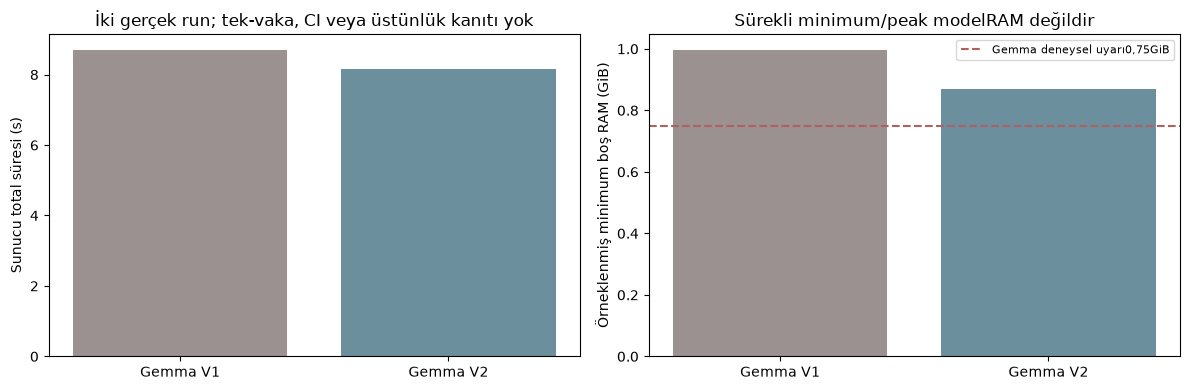

In [4]:

rows=pd.DataFrame(read(Q/'real_comparison_v1_v2_Qwen_NOT_RUN.json')['rows'])
display(rows[['model_method','experiment_status','pipeline_terminal_status','pipeline_schema_status','independent_content_schema_status','actual_language_agent','source_faithfulness_agent','primary_quote_kind_alignment','human_review','actual_server_prompt_tokens','output_tokens','server_total_seconds']])
fig,axes=plt.subplots(1,2,figsize=(12,4))
real=rows.iloc[:2]
axes[0].bar(real.model_method,real.server_total_seconds,color=['#9b9191','#6b8f9d'])
axes[0].set(ylabel='Sunucu total süresi (s)',title='İki gerçek run; tek-vaka, CI veya üstünlük kanıtı yok')
axes[1].bar(real.model_method,real.sampled_min_free_RAM_GiB,color=['#9b9191','#6b8f9d'])
axes[1].axhline(.75,color='#b06060',ls='--',label='Gemma deneysel uyarı0,75GiB')
axes[1].set(ylabel='Örneklenmiş minimum boş RAM (GiB)',title='Sürekli minimum/peak modelRAM değildir');axes[1].legend(fontsize=8)
plt.tight_layout();plt.savefig(F/'real_V1_V2_latency_and_sampled_memory.png',dpi=160);plt.show()


**Yorum:** V2 kaynak çekirdeğinde V1'e göre daha iyi görünüyor fakat Türkçe görevi başarısız; token protokolü de FAIL. Bu aynı görülmüş vaka üstünde geliştirme karşılaştırmasıdır; bağımsız genelleme/klinik doğruluk veya genel model üstünlüğü değildir. Ham response/message JSON ve CSV'de aynen korunur. Qwen için sayı/puan çizilmez: NOT_RUN.

## Qwen kimliği, modele özel bellek planı ve durma

,model,yerel_digest,model_bytes,full_FP16_KV_MiB,API_identity
0,qwen3:4b-instruct-2507-q4_K_M,sha256:0edcdef34593eac1aa2be9c7d06c432dcf81945adca5eca2f27662c18f168ba0,2497280480,288.0,PENDING_NORMAL_USER_POWERSHELL_NO_APPCONTAINER_CALL


,mediaType,size,digest,SHA_verified
0,application/vnd.docker.container.image.v1+json,487,sha256:b72accf9724e93698c57cbd3b1af2d3341b3d05ec2089d86d273d97964853cd2,True
1,application/vnd.ollama.image.model,2497280480,sha256:85e4a5b7b8ef0e48af0e8658f5aaab9c2324c76c1641493f4d1e25fce54b18b9,True
2,application/vnd.ollama.image.template,1379,sha256:eade0a07cac7712787bbce23d12f9306adb4781d873d1df6e16f7840fa37afec,True
3,application/vnd.ollama.image.license,11338,sha256:d18a5cc71b84bc4af394a31116bd3932b42241de70c77d2b76d69a314ec8aa12,True
4,application/vnd.ollama.image.params,119,sha256:0914c7781e001948488d937994217538375b4fd8c1466c5e7a625221abd3ea7a,True


,Qwen_ayrı_plan
version,WP12-QWEN4B-CONDITIONAL-MEMORY-v1
RAM_floor_bytes,3221225472
GPU_floor_MiB,3584
commit_floor_bytes,4294967296
runtime_RAM_floor_bytes,1073741824
runtime_commit_floor_bytes,1073741824
OS_pressure_signal_required,True
automatic_threshold_lowering,False
safety_guarantee,False
basis,Existing Qwen3GiB host floor retained; GPU ceil0.25GiB(model file+full FP16 KV+0.75GiB unmeasured runtime allowance); commit4GiB; assumptions not measured peak.


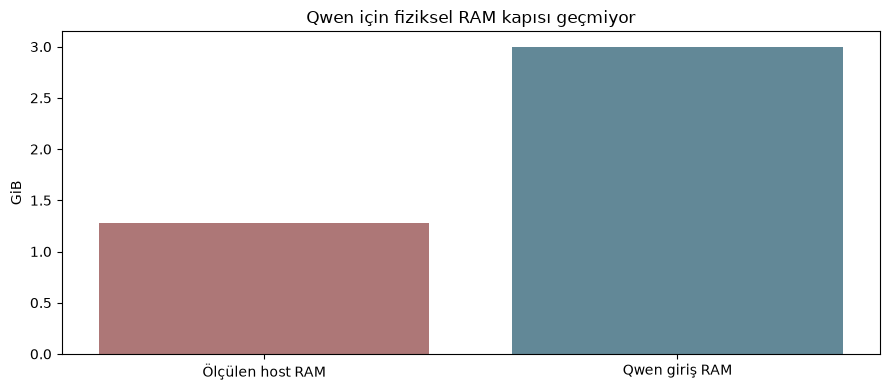

In [5]:

res=read(Q/'Qwen_cache_and_resource_assessment.json')
policy=read(ROOT/'configs/WP12_QWEN4B_CONDITIONAL_MEMORY_v1.json')
display(pd.DataFrame([{'model':res['model'],'yerel_digest':res['local_registered_digest'],
 'model_bytes':res['model_bytes'],'full_FP16_KV_MiB':res['full_FP16_KV_bytes_at_2048']/2**20,
 'API_identity':res['API_digest_current']}]))
display(pd.DataFrame(res['layer_hashes']))
display(pd.DataFrame([policy]).T.rename(columns={0:'Qwen_ayrı_plan'}))
m=read(Q/'Qwen_current_memory_snapshot.json')
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(['Ölçülen host RAM','Qwen giriş RAM'],[m['memory']['available_bytes']/2**30,3],color=['#ad7777','#628897'])
ax.set(ylabel='GiB',title='Qwen için fiziksel RAM kapısı geçmiyor')
plt.tight_layout();plt.savefig(F/'Qwen_host_RAM_gate_BLOCKED.png',dpi=160);plt.show()


**Yorum:** Yerel Qwen digest0edc… tarihsel kayıtla aynı;2.497.280.480bayt model ve config/template/license/params hash'leri doğrulandı.36katman/8KVhead/key128/value128 için2048context tam FP16 KV288MiB teorik hesap; gerçek runtime peak değildir. Qwen ayrı giriş:RAM3GiB,VRAM3,5GiB,commit4GiB, OSfalse. VRAM tabanı model+KV+0,75GiB varsayımsal çalışma marjının yukarı0,25GiB yuvarlanmasıdır; ölçülmüş peak veya güvenlik garantisi değil. Eski Qwen3GiB host tabanı korunur; Gemma düşük eşikleri kopyalanmaz.

Son RAM1,275GiB<3; VRAM3935MiB ve commit ölçümleri yeterli olsa bile host kapısı FAIL. API digest ve tam Qwen tokenizer sayısı PENDING/UNKNOWN; AppContainer'dan API zorlanmadı. Qwen inference NOT_RUN ve yürütücü/istek komutu açılmadı. Uygun gerçek kaynak koşulları sonradan oluşursa mevcut koşullu yetkiyle API/template/token/bellek kapıları tamamlanıp en fazla bir Qwen denemesi hazırlanabilir; otomatik riskli eşik düşürülmez.32 test geçti.19×3 ve WP13 kapalı; yeni inference/indirme/eğitim/yayın yok.